# Comparison of urban indicators in Tampere and Helsinki, Finland

## 1. Introduction
The following notebook calculates some urban indicators for Tampere and Helsinki. In section 2, data and methods used in the study will be introduced in more detail. In section 3, the bicycle networks of the cities will be analyzed both in terms of traditional statistics and in terms of spatial properties of the network using data from OpenStreetMap.org (later **OSM**). The spatial properties of the network can be divided into geometric and topological properties, where geometric properties only consider the geometry of the objects and topological properties tell something about the relationships between the nodes and edges in the network. Geometric properties include attributes such as length of the edges and the area of their total hull whereas topological properties include attributes such as centrality and node degree. Section 4 will concentrate on analyzing urban growth in Tampere and Helsinki. Urban growth is an interesting indicator to compare between these cities, as both are rapidly developing cities, some of the fastest growing cities in Finland.

The aim of the study is to compare the bicycle network of the cities to see if there are some interesting differences between the two networks. Some interesting measures for the comparison, such as amount and geometries of network components, will be calculated for both cities. Another aim of the study is to compare and visualize the urban growth of the cities from 2016 to 2020 using data from **Statistics Finland**. The growth will be visualized with maps and graphs to detect patterns in the data.

## 2. Methods and data
Although the processes for network analysis and urban growth analysis are quite different, `matplotlib` and `pandas` Python libraries are used quite extensively throutout the study. Following subsections go deeper into detail of analyzing both indicators. The methods for analyses are organized as separate Python modules, `street_network_metrics` and `urban_growth_metrics`. The notebook used in the study contains quite extensive logging and the logs can be found from `logs` directory, if the logging is set on and the code cells are being run. Input data, if not downloaded on demand, can be found from `data` directory. The `osmnx` library will populate `cache` directory with OpenStreetMap
### 2.1 Bicycle network analysis data and methods
Data from OpenStreetMap.org (OSM) will be used for analyzing the bicycle networks of the two cities. The data is fetched using `osmnx` which is a mature Python library for fetching data from OSM via Nominatim geocoder and Overpass API. `pandas` and `geopandas` Python libraries will be used for calculating traditional and spatial statistics for the data whereas `osmnx` and `networkx` libraries will be used for collecting topological information from the spatial networks.

The spatial network fetched using `osmnx` contains a column `highway`, which contains a single or multiple categories the edge of the network belongs to. The value counts for the categories will be calculated both in terms of mutually inexclusive categories and mutually exclusive sets of categories and joined together using the categories or the set of categories as keys. The counts are then printed as tables and shown as bar charts. 

The code for the analysis is organized as a separate Python module `street_network_metrics` which contains functions that are used to compute network statistics for the two cities. Visualizing is mostly in the notebook itself.   
### 2.2 Urban growth analysis data and methods
Data from Statistics Finland will be used for studying the urban growth of the cities. The data sets used for the comparison are the *Population grid data 1 km x 1 km* and *Municipalities, key figures* data sets from 2016 to 2020. The data is downloaded from *Paituli.csc.fi* service using their WFS service, analyzed with `pandas` and `geopandas` and plotted using `matplotlib`.

## 3. Bicycle network analysis
Both analyses will be started by importing necessary libraries 

In [1]:
# This needs to be here to download one needed library
!pip install OWSLib

import pathlib
import os
import logging
for dir_name in ('logs', 'data', 'docs'):
    if not os.path.exists(dir_name):
        os.makedirs(dir_name)
NOTEBOOK_PATH = pathlib.Path().resolve()
LOG_DIRECTORY = NOTEBOOK_PATH / 'logs'
logger = logging.getLogger(__name__)
logging.basicConfig(level=logging.DEBUG, 
                    format='%(asctime)s %(levelname)-8s %(message)s', 
                    datefmt='%a, %d %b %Y %H:%M:%S', 
                    filename=LOG_DIRECTORY / 'FAlog.log', filemode='w')
#logging.disable(logging.NOTSET)

DATA_DIRECTORY = NOTEBOOK_PATH / "data"
OUTPUT_DIRECTORY = NOTEBOOK_PATH / "docs"
# Most necessary imports
import json

import geopandas as gpd
import pandas as pd
# import requests
# from datetime import datetime
import matplotlib.pyplot as plt
# import contextily as cx
import networkx as nx
import osmnx as ox

# Import everything that is needed for calculating network
# network statistics and comparing them city-wise
from street_network_metrics import *
# Set counter for table caption numbers
global tcounter
tcounter = 0

os.environ['PROJ_LIB'] = '/path/to/env/share/proj'
#os.environ['GDAL_DATA'] = '/path/to/env/share/'
pd.set_option("display.max_rows", 50)

# Define the cities used in the analyses
CITIES = CITY1, CITY2 = ('Helsinki, Finland', 'Tampere, Finland')
logger.info('Notebook starts. Cities selected: {c1}; {c2}.'.format(c1=CITY1, c2=CITY2))
logger.info('Calculating network statistics')

### 3.1 Downloading data
Download the graphs for both cities. This will take few minutes since the graphs are quite large.

In [2]:
# nets_t = get_networks([])
# for G in nets:
#     print(f)
nets = { c: {'graph': g} for c, g in [get_network(city) for city in CITIES]}

Print the graphs as a sanity check:

In [3]:
print(type(nets))
print(len(nets.keys()))
for key in nets:
    print(nets[key])
    #ox.plot_graph(G)

<class 'dict'>
2
{'graph': <networkx.classes.multidigraph.MultiDiGraph object at 0x7ffa5c4a6860>}
{'graph': <networkx.classes.multidigraph.MultiDiGraph object at 0x7ffa7a4701f0>}


### 3.2 The distribution of roadlink types
Convert the graphs to GeoDataFrames which contain nodes and edges for both cities. Then 
make a graph dict which has the following form:
```
{
    cityname::string: {
        {
            'graph': <networkx.MultiDiGraph>,
            .
            .
            .
            other keys
        }
    }
    
    other cities
}    
```

In [4]:
gdf_dict = graphs_to_gdfs(nets)


In [5]:
total_counts_exp, total_counts = join_highway_type_counts(gdf_dict, 'highway', 'Roadlink types', CITIES)
total_counts_exp = total_counts_exp.set_index('Roadlink types')
total_counts = total_counts.set_index('Roadlink types')
print(total_counts_exp.info())
print(total_counts.info())

<class 'pandas.core.frame.DataFrame'>
Index: 18 entries, service to road
Data columns (total 2 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   Count (Helsinki, Finland)  17 non-null     Int64
 1   Count (Tampere, Finland)   17 non-null     Int64
dtypes: Int64(2)
memory usage: 468.0+ bytes
None
<class 'pandas.core.frame.DataFrame'>
Index: 89 entries, service to tertiary, primary
Data columns (total 2 columns):
 #   Column                     Non-Null Count  Dtype
---  ------                     --------------  -----
 0   Count (Helsinki, Finland)  77 non-null     Int64
 1   Count (Tampere, Finland)   59 non-null     Int64
dtypes: Int64(2)
memory usage: 2.3+ KB
None


In [6]:
def captioned_table(df, f_str, format_keys):
    """
    A small function that returns a numbered captioned data table 
    with very nice formatting.
    
    """
    
    def numbered_table_caption(f_str):
        global tcounter
        tcounter += 1
        return 'Table {tc}. '.format(tc=tcounter) + f_str 
    
    styled = df.style.set_table_attributes("style='display:inline'")
    styled = styled.set_caption(numbered_table_caption(f_str).format(**format_keys))
    return styled

In [7]:
total_counts_styled_exp = captioned_table(total_counts_exp, 
                                      ('Number of roadlinks per roadlink type in {city1} and {city2}. ' 
                                       'Some roadlinks belong to several categories.'), dict(city1=CITY1, city2=CITY2))
total_counts_styled_exp

,"Count (Helsinki, Finland)","Count (Tampere, Finland)"
Roadlink types,,
service,51085,23508
cycleway,46939,22910
residential,31651,18239
path,30436,26578
tertiary,7840,4195
secondary,5747,1790
unclassified,5606,3018
track,2310,4163
pedestrian,1714,168


And the same, more visually, as a bar chart. Logaritmic scale will be used to be able to differentiate groups which have only very few members.

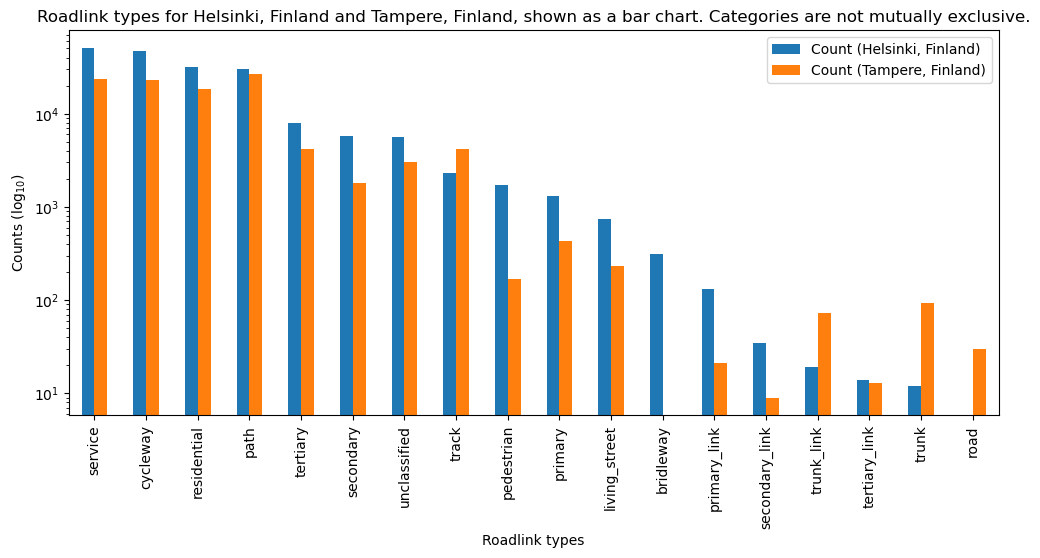

In [8]:
bars_types = total_counts_exp.plot(kind='bar', figsize=(12,5), 
                  logy=True,
                  xlabel='Roadlink types', 
                  ylabel='Counts (log$_{10}$)', 
                  title=('Roadlink types for {c1} and {c2}, shown as a bar chart. '
                         'Categories are not mutually exclusive.').format(c1=CITY1, c2=CITY2))

In [9]:
styled_value_counts = captioned_table(total_counts, ('Roadlink type sets for {city1} and {city2}. ' 
                                       'Some roadlinks belong to several categories but the sets are exclusive.'), 
                                      dict(city1=CITY1, city2=CITY2))

As in the original data the `highway` column was populated with nonnormalized, list-like data, they had to be transformed to strings and joined on the then-formed strings. What we get is a very long list of categories, or sets, of categories. Some elements in the of list roadlink type sets only occur few times but some sets   

In [10]:
styled_value_counts

,"Count (Helsinki, Finland)","Count (Tampere, Finland)"
Roadlink types,,
service,49466,22586
cycleway,45615,22066
residential,30149,17110
path,29704,25866
tertiary,7823,4186
secondary,5735,1787
unclassified,5345,2925
track,2052,3821
pedestrian,1502,156


And the same, more visually, as a bar chart. Logaritmic scale will be used to be able to differentiate groups which have only very few members.

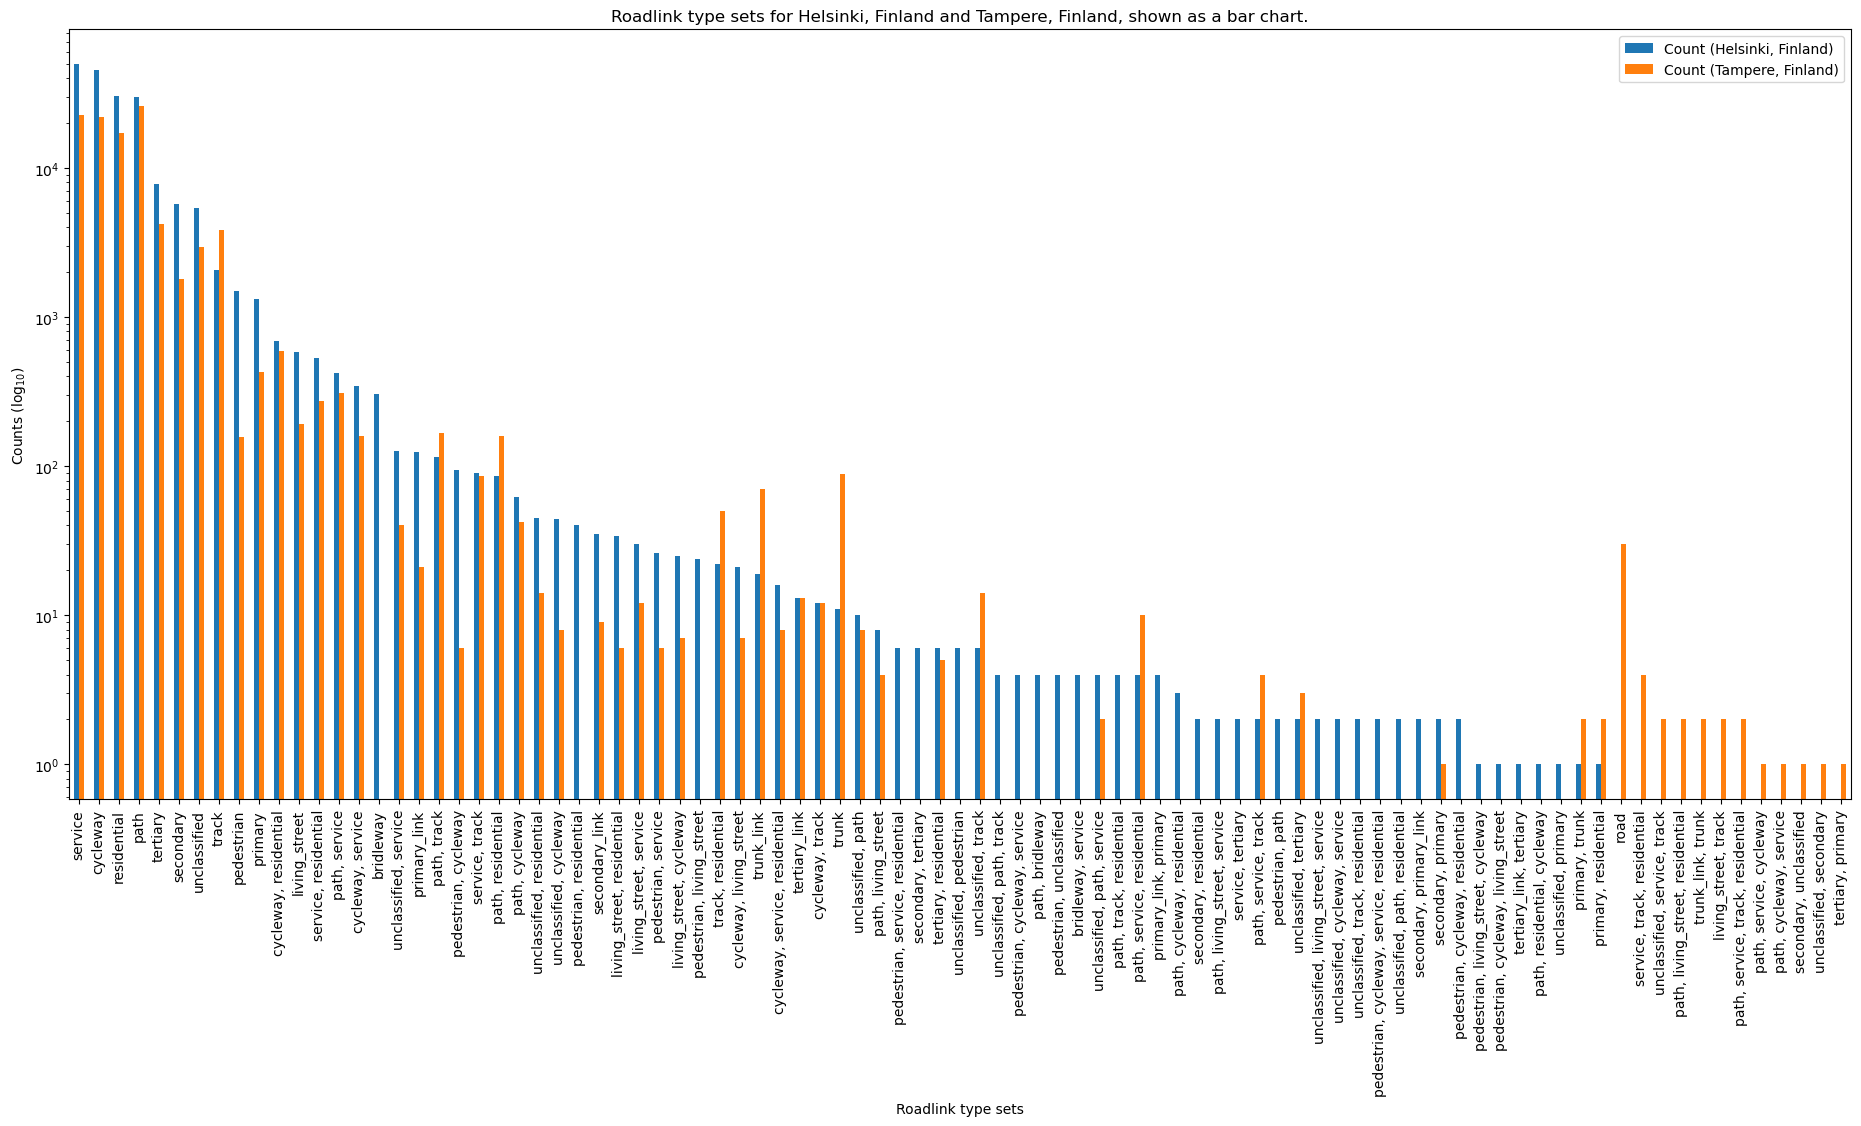

In [11]:
bars_type_sets = total_counts.plot(kind='bar', figsize=(23,10), 
                  logy=True,
                  xlabel='Roadlink type sets', 
                  ylabel='Counts (log$_{10}$)', 
                  title='Roadlink type sets for {c1} and {c2}, shown as a bar chart.'.format(c1=CITY1, c2=CITY2))

The bar chart for roadlink type sets reveal interesting information. Tampere does not have any links labeled as bridleways whereas Helsinki has few hundred of those, which was also apparent in the previous bar chart for roadlink types. Also, Tampere has 30 roads which are designated for bicycles whereas Helsinki does not have any. Finally, Helsinki has much more uniform distribution of different sets than Tampere which lacks many sets present in Helsinki data.

### 3.3 Geometric and topological analysis
Let's perform the geometric and topological analysis for the networks. Let's begin by extracting convex hulls for both network edges.

In [31]:
def basic_stats_for_graphs(cities, graph_obj):
    """
    Populates graph object with convex hulls, their areas 
    and basic stats for the cities. Seperates non-elementary columns such as
    "street_per_node_counts" and "street_per_node_proportions" as separate
    value for easier analysis.
    
    Parameters:
    -----------
        cities::tuple(str): A tuple of city names
        graph_obj::dict   : Dictionary containing data for the cities´ graphs
    
    Return:
        graph_obj::dict   : Dictionary containing data for the cities´ graphs, including 
                            convex hull, its area and basic stats
    """
    for city in CITIES:
        edges = graph_obj[city]['edges']
        graph = graph_obj[city]['graph']
        logger.info('Calculating convex hull for {}'.format(city))
        convex_hull = edges.unary_union.convex_hull
        graph_obj[city]['convex_hull'] = gpd.GeoDataFrame(index=[0], data={'city': [city]}, geometry=[convex_hull], crs=edges.crs)
        logger.info('Convex hull calculated and converted to GeoDataFrame'.format(city))
        graph_obj[city]['hull_area'] = convex_hull.area
        logger.info('Calculating basic stats for {}'.format(city))
        b_stats = pd.Series(ox.basic_stats(graph, area=convex_hull.area))
        streets_per_node_counts = b_stats['streets_per_node_counts']
        streets_per_node_proportions = b_stats['streets_per_node_proportions']
        graph_obj[city]['streets_per_node_proportions'] = streets_per_node_proportions
        graph_obj[city]['streets_per_node_counts'] = streets_per_node_counts
        b_stats.drop(labels=['streets_per_node_proportions', 'streets_per_node_counts'], inplace=True)
        graph_obj[city]['basic_stats_elementary'] = b_stats
        logger.info('Basic stats DONE'.format(city))
    return graph_obj

for city in CITIES:
    edges = gdf_dict[city]['edges']
    graph = gdf_dict[city]['graph']
    convex_hull = edges.unary_union.convex_hull
    # hull_dict = 
    gdf_dict[city]['convex_hull'] = gpd.GeoDataFrame(index=[0], data={'city': [city]}, geometry=[convex_hull], crs=edges.crs)
    gdf_dict[city]['convex_hull'].plot()
    gdf_dict[city]['hull_area'] = convex_hull.area
    gdf_dict[city]['basic_stats'] = ox.basic_stats(graph, area=convex_hull.area)

In [32]:
graph_dict = basic_stats_for_graphs(CITIES, gdf_dict)

Obtain values for the basic stats for both cities

In [37]:
b_stats_city1 = graph_dict[CITY1]['basic_stats_elementary']
streets_per_node_counts_city1 = graph_dict[CITY1]['streets_per_node_counts']
streets_per_node_proportions_city1 = graph_dict[CITY1]['streets_per_node_proportions']
b_stats_city2 = graph_dict[CITY2]['basic_stats_elementary']
streets_per_node_counts_city2 = graph_dict[CITY2]['streets_per_node_counts']
streets_per_node_proportions_city2 = graph_dict[CITY2]['streets_per_node_proportions']
#graph_obj[city]['basic_stats_elementary'] = b_stats

In [40]:
basic_stats_df = pd.DataFrame({CITY1: b_stats_city1, CITY2: b_stats_city2})
basic_stats_df["Difference"] = basic_stats_df[CITY1] - basic_stats_df[CITY2]

In [49]:
basic_stats_df.loc['n']

Helsinki, Finland    73242
Tampere, Finland     37863
Difference           35379
Name: n, dtype: object

In [45]:
styled_elementary_basic_stats = captioned_table(basic_stats_df, 
                                                'Basic geometric and topological network stats for {city1} and {city2}.' ,
                                                 dict(city1=CITY1, city2=CITY2))
styled_elementary_basic_stats

,"Helsinki, Finland","Tampere, Finland",Difference
n,73242,37863,35379
m,182820,103396,79424
k_avg,4.992218,5.461585,-0.469368
edge_length_total,8235819.239000,7836602.734000,399216.505000
edge_length_avg,45.048787,75.792127,-30.743340
streets_per_node_avg,2.645681,2.810369,-0.164688
intersection_count,53764,30531,23233
street_length_total,4348046.188000,3996164.069000,351882.119000
street_segment_count,96859,53099,43760
street_length_avg,44.890472,75.258744,-30.368273


filtered = list(filter(lambda x: type(x) == dict, list(graph_dict[CITY1]['basic_stats'])))

left = pd.DataFrame(graph_dict[CITY1]['basic_stats'],graph_dict[CITY2]['basic_stats'])
right = pd.DataFrame.from_dict(graph_dict[CITY2]['basic_stats'], orient='index').reset_index()

joined_stats = left.merge(right, on='index')
s_per_n_counts = (joined_stats.loc[6, '0_x'], joined_stats.loc[6, '0_y'])
for elem in s_per_n_counts:
    
    print(elem)

## 4. Urban growth in Tampere and Helsinki between 2016 and 2020

In [2]:
logger.info('Calculating urban growth metrics')
YEARS = (2016,2017,2018,2019,2020)
WFS_LAYER_PREFIXES = GRIDS, MUNS = ('paituli:tike_vaki1km_','paituli:tike_kuntienVaesto_')
from urban_growth_metrics import *

### 4.1 Downloading population data

First, the population grid will be loaded for the time period from 2016 to 2020 for both Tampere and Helsinki seperately. We'll likely not need all of those data frames, but there might be some usage for them so better download everything at once.

In [3]:
# Grid layers for Helsinki
grid_layers_city1 = get_wfs_time_series(GRIDS, YEARS, [CITY1], "kunta", "https://paituli.csc.fi/geoserver/paituli/wfs?")
print("Number of layers:", len(grid_layers_city1.keys()))
for key, gdf in grid_layers_city1.items():
    print(key)
    print(gdf['kunta'].unique())
    print(list(gdf.columns.values))
    print(len(gdf))
    #gdf.plot()
    #print(grid_layers[key].head())

Number of layers: 5
paituli:tike_vaki1km_2016
['091']
['id', 'gml_id', 'kunta', 'grd_id', 'id_nro', 'xkoord', 'ykoord', 'vaesto', 'miehet', 'naiset', 'ika_0_14', 'ika_15_64', 'ika_65_', 'geometry']
232
paituli:tike_vaki1km_2017
['091']
['id', 'kunta', 'grd_id', 'id_nro', 'xkoord', 'ykoord', 'vaesto', 'miehet', 'naiset', 'ika_0_14', 'ika_15_64', 'ika_65_', 'geometry']
231
paituli:tike_vaki1km_2018
['091']
['id', 'kunta', 'grd_id', 'id_nro', 'xkoord', 'ykoord', 'vaesto', 'miehet', 'naiset', 'ika_0_14', 'ika_15_64', 'ika_65_', 'geometry']
230
paituli:tike_vaki1km_2019
['091']
['id', 'kunta', 'grd_id', 'id_nro', 'xkoord', 'ykoord', 'vaesto', 'miehet', 'naiset', 'ika_0_14', 'ika_15_64', 'ika_65_', 'geometry']
231
paituli:tike_vaki1km_2020
['091']
['id', 'grd_id', 'id_nro', 'xkoord', 'ykoord', 'kunta', 'vaesto', 'miehet', 'naiset', 'ika_0_14', 'ika_15_64', 'ika_65_', 'geometry']
232


Then map them into dictionary using the year as a key for the entries:

In [4]:
city1_grids_by_year = [(int(typename.split("_")[-1]), gdf) for typename, gdf in grid_layers_city1.items()]

In [5]:
# Grid layers for Tampere
grid_layers_city2 = get_wfs_time_series(GRIDS, YEARS, [CITY2], "kunta", "https://paituli.csc.fi/geoserver/paituli/wfs?")
print("Number of layers:", len(grid_layers_city2.keys()))
for key, gdf in grid_layers_city2.items():
    print(key)
    print(gdf['kunta'].unique())
    print(list(gdf.columns.values))
    print(len(gdf))
    #gdf.plot()
    #print(grid_layers[key].head())

Number of layers: 5
paituli:tike_vaki1km_2016
['837']
['id', 'gml_id', 'kunta', 'grd_id', 'id_nro', 'xkoord', 'ykoord', 'vaesto', 'miehet', 'naiset', 'ika_0_14', 'ika_15_64', 'ika_65_', 'geometry']
446
paituli:tike_vaki1km_2017
['837']
['id', 'kunta', 'grd_id', 'id_nro', 'xkoord', 'ykoord', 'vaesto', 'miehet', 'naiset', 'ika_0_14', 'ika_15_64', 'ika_65_', 'geometry']
444
paituli:tike_vaki1km_2018
['837']
['id', 'kunta', 'grd_id', 'id_nro', 'xkoord', 'ykoord', 'vaesto', 'miehet', 'naiset', 'ika_0_14', 'ika_15_64', 'ika_65_', 'geometry']
441
paituli:tike_vaki1km_2019
['837']
['id', 'kunta', 'grd_id', 'id_nro', 'xkoord', 'ykoord', 'vaesto', 'miehet', 'naiset', 'ika_0_14', 'ika_15_64', 'ika_65_', 'geometry']
439
paituli:tike_vaki1km_2020
['837']
['id', 'grd_id', 'id_nro', 'xkoord', 'ykoord', 'kunta', 'vaesto', 'miehet', 'naiset', 'ika_0_14', 'ika_15_64', 'ika_65_', 'geometry']
443


Same for Tampere data

In [6]:
city2_grids_by_year = [(int(typename.split("_")[-1]), gdf) for typename, gdf in grid_layers_city2.items()]

Then download the municipal level layers for Helsinki and Tampere, separately.

In [7]:
# Helsinki municipal layers
mun_layers_city1 = get_wfs_time_series(MUNS, YEARS, [CITY1], "kunta", "https://paituli.csc.fi/geoserver/paituli/wfs?")
print("Number of layers:", len(mun_layers_city1.keys()))
for key, gdf in mun_layers_city1.items():
    print(key)
    print(gdf['kunta'].unique())
    print(list(gdf.columns.values))
    print(len(gdf))
    #gdf.plot()
    #print(grid_layers[key].head())

Number of layers: 5
paituli:tike_kuntienVaesto_2016
['091']
['id', 'kunta', 'nimi', 'namn', 'vaesto', 'vaesto_p', 'miehet', 'miehet_p', 'naiset', 'naiset_p', 'ika_0_14', 'ika_0_14p', 'ika_15_64', 'ika_15_64p', 'ika_65_', 'ika_65_p', 'geometry']
1
paituli:tike_kuntienVaesto_2017
['091']
['id', 'kunta', 'nimi', 'namn', 'vaesto', 'vaesto_p', 'miehet', 'miehet_p', 'naiset', 'naiset_p', 'ika_0_14', 'ika_0_14p', 'ika_15_64', 'ika_15_64p', 'ika_65_', 'ika_65_p', 'geometry']
1
paituli:tike_kuntienVaesto_2018
['091']
['id', 'kunta', 'nimi', 'namn', 'name', 'vaesto', 'vaesto_p', 'miehet', 'miehet_p', 'naiset', 'naiset_p', 'ika_0_14', 'ika_0_14p', 'ika_15_64', 'ika_15_64p', 'ika_65_', 'ika_65_p', 'geometry']
1
paituli:tike_kuntienVaesto_2019
['091']
['id', 'kunta', 'nimi', 'namn', 'name', 'vaesto', 'vaesto_p', 'miehet', 'miehet_p', 'naiset', 'naiset_p', 'ika_0_14', 'ika_0_14p', 'ika_15_64', 'ika_15_64p', 'ika_65_', 'ika_65_p', 'geometry']
1
paituli:tike_kuntienVaesto_2020
['091']
['id', 'kunta', 

Then map them into dictionary using the year as a key for the entries:

In [8]:
city1_muns_by_year = [(int(typename.split("_")[-1]), gdf) for typename, gdf in mun_layers_city1.items()]

In [9]:
# Tampere municipal layers
mun_layers_city2 = get_wfs_time_series(MUNS, YEARS, [CITY2], "kunta", "https://paituli.csc.fi/geoserver/paituli/wfs?")
print("Number of layers:", len(mun_layers_city2.keys()))
for key, gdf in mun_layers_city2.items():
    print(key)
    print(gdf['kunta'].unique())
    print(list(gdf.columns.values))
    print(len(gdf))
    #gdf.plot()
    #print(grid_layers[key].head())

Number of layers: 5
paituli:tike_kuntienVaesto_2016
['837']
['id', 'kunta', 'nimi', 'namn', 'vaesto', 'vaesto_p', 'miehet', 'miehet_p', 'naiset', 'naiset_p', 'ika_0_14', 'ika_0_14p', 'ika_15_64', 'ika_15_64p', 'ika_65_', 'ika_65_p', 'geometry']
1
paituli:tike_kuntienVaesto_2017
['837']
['id', 'kunta', 'nimi', 'namn', 'vaesto', 'vaesto_p', 'miehet', 'miehet_p', 'naiset', 'naiset_p', 'ika_0_14', 'ika_0_14p', 'ika_15_64', 'ika_15_64p', 'ika_65_', 'ika_65_p', 'geometry']
1
paituli:tike_kuntienVaesto_2018
['837']
['id', 'kunta', 'nimi', 'namn', 'name', 'vaesto', 'vaesto_p', 'miehet', 'miehet_p', 'naiset', 'naiset_p', 'ika_0_14', 'ika_0_14p', 'ika_15_64', 'ika_15_64p', 'ika_65_', 'ika_65_p', 'geometry']
1
paituli:tike_kuntienVaesto_2019
['837']
['id', 'kunta', 'nimi', 'namn', 'name', 'vaesto', 'vaesto_p', 'miehet', 'miehet_p', 'naiset', 'naiset_p', 'ika_0_14', 'ika_0_14p', 'ika_15_64', 'ika_15_64p', 'ika_65_', 'ika_65_p', 'geometry']
1
paituli:tike_kuntienVaesto_2020
['837']
['id', 'kunta', 

Then map them into dictionary using the year as a key for the entries:

In [10]:
city2_muns_by_year = [(int(typename.split("_")[-1]), gdf) for typename, gdf in mun_layers_city2.items()]

grid_joined = time_series_from_geodataframes(grids_by_year, key='grd_id', columns=[])
grid_joined.info()

We now have a grid which is populated with all the common columns in the dataframes from each year. The `geometry` shown is the geometry from 2016, i.e. the first in the list of dataframes. We could just as well use any of the other geometry columns, but when it comes to population grid, the grid has most likely been geometrically similar between those years. We will then continue on downloading the municipal level data.

# First, let's create a list of year,GeoDataFrame pairs
muns_by_year = [(int(typename.split("_")[-1]), gdf) for typename, gdf in mun_layers.items()]

# Join the municipality layers with municipality code.
municipalities_joined = time_series_from_geodataframes(muns_by_year, key='kunta', columns=[])


municipalities_joined.plot()

grid_joined.info()
grid_joined.plot(column='vaesto_2020', cmap="Reds", scheme="NaturalBreaks")

### 4.2 Data processing and analysis
We now have at least most of the raw data needed for analyzing the population growth in Helsinki and Tampere. We will continue on processing the data into more visually attractive and more statistically descriptive form.

In [11]:
vaesto_city1_timeseries = time_series_from_geodataframes(city1_muns_by_year, columns=[], axis=0).drop(["geometry", "id", "nimi", "namn", "kunta"], axis=1)
print(list(vaesto_city1_timeseries.columns.values))
df = vaesto_city1_timeseries.copy(deep=True)
df['diff_miehet'] = df['miehet'].diff()
#df = df.set_axis(["2016-2017", "2017-2018", "2018-2019", "2019-2020"])
#df = df.set_axis(['miehet', 'ika_0_14p', 'vaesto_p', 'ika_15_64', 'ika_65_p', 'ika_0_14', 'naiset_p', 'ika_65_', 'ika_15_64p', 'vaesto', 'miehet_p', 'naiset'], axis=1)

['naiset', 'ika_15_64p', 'miehet', 'miehet_p', 'ika_15_64', 'ika_0_14', 'ika_65_p', 'ika_65_', 'vaesto_p', 'vaesto', 'naiset_p', 'ika_0_14p']


In [12]:
renaming = {'miehet': 'Miehet', 'ika_15_64': 'Väestö, 15-64 vuotta', 'ika_0_14': 'Väestö, 0-14 vuotta', 'ika_65_': "Väestö, yli 65 vuotta", 'vaesto': 'Koko väestö', 'naiset': "Naiset"}
{'miehet': 'Miehet', 'ika_15_64': 'Väestö, 15-64 vuotta', 'ika_65_': 'ika_65_', 'diff_naiset': 'naiset', 'diff_vaesto': 'vaesto', 'diff_ika_0_14': 'ika_0_14'}
df_diff = timeseries_diff(vaesto_city1_timeseries, ['miehet', 'ika_15_64', 'ika_0_14', 'ika_65_', 'vaesto', 'naiset'], rename_map=renaming)

In [13]:
df_diff_p = timeseries_diff(vaesto_city1_timeseries, ['miehet', 'ika_15_64', 'ika_0_14', 'ika_65_', 'vaesto', 'naiset'], rename_map=renaming, percentage_change=True)

In [14]:
df_diff_p = df_diff_p.mul(100)